<a href="https://colab.research.google.com/github/Jonatham1542/Proyecto-Tornado/blob/main/Tornadofinal_con_resultados_PC_f.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


#  Simulación computacional del movimiento del aire en un tornado

### Universidad Industrial de Santander
**Algoritmos Computacionales — Proyecto final**

**Integrantes:**
- Jonathan David Peña Sanchez - 2250080
- Alfredo Jose Moreno Salazar - 2200800
- Nicolas Stephen Ardila Rodriguez - 2250078
- Andres Felipe Mendez Malaver - 2250797

---

## Introducción

Los tornados presentan movimientos rotacionales intensos del aire. Aunque su comportamiento real involucra fenómenos atmosféricos complejos, su componente giratoria puede representarse mediante modelos matemáticos simplificados.

En este proyecto utilizamos el **modelo de vórtice de Rankine** para calcular las velocidades del aire y simular el desplazamiento de partículas.

Además, implementamos el mismo algoritmo de dos maneras: **serial y paralela**, con el objetivo de comparar sus tiempos de ejecución y evaluar el rendimiento computacional.

## Objetivo general

Modelar el movimiento giratorio del aire mediante un vórtice de Rankine y comparar el rendimiento de las implementaciones serial y paralela en Python.

## Objetivos específicos

1. Implementar matemáticamente el campo de velocidades.
2. Simular el movimiento de partículas mediante RK2.
3. Visualizar el fenómeno mediante gráficas y animaciones.
4. Verificar que las versiones serial y paralela producen resultados equivalentes.
5. Medir los tiempos, el speedup y la eficiencia computacional.



## 1. Modelo físico: vórtice de Rankine

El vórtice de Rankine es un modelo idealizado que describe el comportamiento de un flujo giratorio alrededor de un eje.

Se divide en dos regiones:

**Región interior:** el fluido presenta una velocidad angular constante. La rapidez tangencial aumenta proporcionalmente a la distancia al centro.

**Región exterior:** la rapidez tangencial disminuye inversamente con la distancia al centro.

La ecuación principal es:

$$
v_\theta(r)=
\begin{cases}
V_{\max}\dfrac{r}{R},&r\le R\\[6pt]
V_{\max}\dfrac{R}{r},&r>R
\end{cases}
$$

Donde:

| Variable | Significado | Unidad |
|---|---|---|
| $r$ | Distancia al centro | m |
| $R$ | Radio del núcleo | m |
| $V_{\max}$ | Rapidez tangencial máxima | m/s |
| $v_\theta$ | Rapidez tangencial local | m/s |

Las componentes cartesianas del campo de velocidades son:

$$
v_x=-v_\theta\frac{y}{r}
\qquad
v_y=v_\theta\frac{x}{r}
$$

En el origen se definen ambas componentes como cero.

### Parámetros iniciales

$$
R=20\ \mathrm{m}
\qquad
V_{\max}=40\ \mathrm{m/s}
$$

Los valores anteriores son parámetros ilustrativos y no corresponden a mediciones de un tornado específico.

---

## 2. Método numérico: Runge-Kutta de segundo orden

Para calcular el desplazamiento de las partículas utilizamos el método del punto medio, conocido como **RK2**.

$$
\mathbf{k}_1=\mathbf{v}(\mathbf{x}_n)
$$

$$
\mathbf{k}_2=
\mathbf{v}\left(\mathbf{x}_n+
\frac{\Delta t}{2}\mathbf{k}_1\right)
$$

$$
\mathbf{x}_{n+1}=\mathbf{x}_n+\Delta t\,\mathbf{k}_2
$$

El algoritmo calcula la velocidad actual, estima una posición intermedia y utiliza esa información para determinar la nueva posición.

## 3. Condiciones iniciales y supuestos

- El movimiento se modela en un plano horizontal bidimensional.
- El campo de velocidades es estacionario e incompresible.
- Las partículas son trazadores que siguen el movimiento local del aire.
- Las posiciones iniciales se generan con una semilla aleatoria fija para reproducir los experimentos.
- No se incluyen turbulencia, fuerzas externas ni movimiento vertical.
- No se imponen paredes físicas; los bordes de las gráficas representan únicamente una ventana de visualización.

**Limitación:** el modelo describe la componente giratoria idealizada de un tornado, no su formación atmosférica completa.

---

## 4. Implementaciones computacionales

### Serial

Las partículas se procesan secuencialmente utilizando un ciclo `range`.

### Paralela

Las partículas se distribuyen entre diferentes hilos mediante Numba y `prange`.

Como las trayectorias se calculan independientemente, no es necesario que diferentes hilos escriban sobre las mismas posiciones.

## 5. Evaluación del rendimiento

El speedup se define como:

$$
S_p=\frac{T_1}{T_p}
$$

Y la eficiencia:

$$
E_p=\frac{S_p}{p}
$$

Donde $T_1$ representa el tiempo serial, $T_p$ el tiempo paralelo con $p$ hilos y $S_p$ la aceleración obtenida.

Para interpretar los resultados se utiliza la ley de Amdahl:

$$
S_p=\frac{1}{(1-f)+f/p}
$$

Aquí $f$ representa la fracción del cálculo que puede paralelizarse.

## 6. Referencias

- [NOAA — Tornado Basics](https://www.nssl.noaa.gov/education/svrwx101/tornadoes/)
- [Wood y White (2011) — Vortex Tangential-Wind Profiles](https://doi.org/10.1175/2011JAS3588.1)
- [Numba — Automatic Parallelization](https://numba.readthedocs.io/en/stable/user/parallel.html)


In [1]:

%pip -q install numpy numba matplotlib pandas ipywidgets psutil

import os
import json
import platform
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import ipywidgets as widgets
import numba
import psutil

from pathlib import Path
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from IPython.display import display, HTML, Markdown, Image, clear_output
from numba import set_num_threads

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

# Carpetas
Path("figuras").mkdir(exist_ok=True)
Path("resultados").mkdir(exist_ok=True)

# Parámetros
R = 20.0
VMAX = 40.0
DT = 0.01
PASOS = 400

# Paleta de colores
AZUL = "#147D92"
NARANJA = "#E59848"
VERDE = "#2C917D"
GRIS = "#94A3B8"

# Estilo gráfico
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.dpi": 105,
    "savefig.dpi": 180
})

print("PROYECTO CONFIGURADO")
print("Python:", platform.python_version())
print("Numba:", numba.__version__)
print("Procesadores lógicos:", os.cpu_count())
print("Máximo configurado en Numba:", numba.config.NUMBA_NUM_THREADS)


PROYECTO CONFIGURADO
Python: 3.13.18
Numba: 0.64.0
Procesadores lógicos: 2
Máximo configurado en Numba: 2


In [2]:

%%writefile modelo_vortice_uis.py

import numpy as np
from numba import njit, prange


# 1. CONDICIONES INICIALES
def iniciar(n, semilla=42, anillos=False, R=20.0):

    if n < 1 or R <= 0:
        raise ValueError("Los parámetros deben ser positivos")

    rng = np.random.default_rng(semilla)
    angulos = rng.uniform(0, 2*np.pi, n)

    if anillos:
        grupos = np.arange(n) % 3
        bases = np.array([0.6*R, 1.7*R, 3.0*R])
        radios = bases[grupos]*rng.uniform(0.96, 1.04, n)
    else:
        radios = np.sqrt(
            rng.uniform(5**2, 85**2, n)
        )

    x = np.ascontiguousarray(
        radios*np.cos(angulos)
    )

    y = np.ascontiguousarray(
        radios*np.sin(angulos)
    )

    return x, y


# 2. CAMPO DE VELOCIDADES
def velocidad(x, y, R, V):

    r2 = np.asarray(x)**2 + np.asarray(y)**2

    omega = np.where(
        r2 <= R*R,
        V/R,
        V*R/np.maximum(r2, 1e-30)
    )

    return -omega*y, omega*x


# 3. MÉTODO RK2
@njit(cache=True)
def rk2(x, y, dt, R, V):

    r2 = x*x + y*y
    omega = V/R if r2 <= R*R else V*R/r2

    # Posición intermedia
    xm = x - 0.5*dt*omega*y
    ym = y + 0.5*dt*omega*x

    rm2 = xm*xm + ym*ym
    wm = V/R if rm2 <= R*R else V*R/rm2

    # Nueva posición
    return x-dt*wm*ym, y+dt*wm*xm


# 4. IMPLEMENTACIÓN SERIAL
@njit(cache=True)
def serial(x0, y0, dt, pasos, R, V):

    x = np.empty_like(x0)
    y = np.empty_like(y0)

    for i in range(len(x0)):

        xi, yi = x0[i], y0[i]

        for k in range(pasos):
            xi, yi = rk2(xi, yi, dt, R, V)

        x[i], y[i] = xi, yi

    return x, y


# 5. IMPLEMENTACIÓN PARALELA
@njit(parallel=True, cache=True)
def paralelo(x0, y0, dt, pasos, R, V):

    x = np.empty_like(x0)
    y = np.empty_like(y0)

    for i in prange(len(x0)):

        xi, yi = x0[i], y0[i]

        for k in range(pasos):
            xi, yi = rk2(xi, yi, dt, R, V)

        x[i], y[i] = xi, yi

    return x, y


# 6. TRAYECTORIAS PARA LA ANIMACIÓN
@njit(cache=True)
def trayectorias(x0, y0, dt, pasos, cada, R, V):

    cuadros = pasos//cada + 1

    xs = np.empty((cuadros, len(x0)))
    ys = np.empty_like(xs)

    x = x0.copy()
    y = y0.copy()

    xs[0, :] = x
    ys[0, :] = y

    for k in range(1, pasos+1):

        for i in range(len(x)):
            x[i], y[i] = rk2(x[i], y[i], dt, R, V)

        if k % cada == 0:
            xs[k//cada, :] = x
            ys[k//cada, :] = y

    return xs, ys


# 7. SOLUCIÓN ANALÍTICA DE REFERENCIA
def exacta(x0, y0, tiempo, R, V):

    r2 = x0*x0 + y0*y0

    omega = np.where(
        r2 <= R*R,
        V/R,
        V*R/np.maximum(r2, 1e-30)
    )

    angulo = omega*tiempo

    return (
        x0*np.cos(angulo)-y0*np.sin(angulo),
        x0*np.sin(angulo)+y0*np.cos(angulo)
    )


Writing modelo_vortice_uis.py


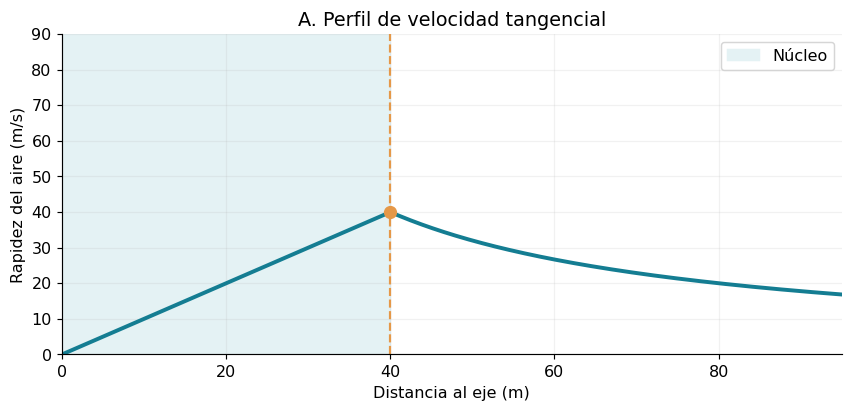

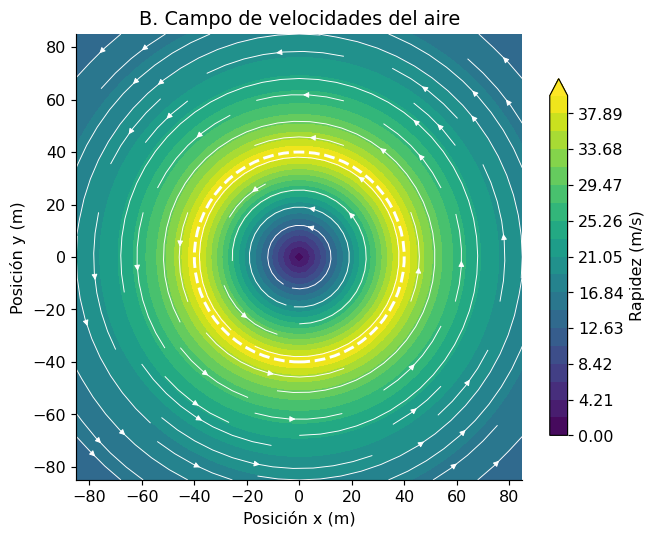

In [3]:

from modelo_vortice_uis import (
    iniciar, velocidad, serial, paralelo,
    trayectorias, exacta
)

def graficas_fisicas(radio=20, viento=40):

    # Gráfica 1: perfil radial
    d = np.linspace(0, 95, 350)

    perfil = np.where(
        d <= radio,
        viento*d/radio,
        viento*radio/np.maximum(d, 1e-30)
    )

    fig, ax = plt.subplots(
        figsize=(8, 3.8),
        layout="constrained"
    )

    ax.axvspan(
        0, radio, color="#E4F2F4",
        label="Núcleo"
    )

    ax.plot(
        d, perfil,
        color=AZUL,
        linewidth=2.7
    )

    ax.axvline(
        radio,
        color=NARANJA,
        linestyle="--",
        linewidth=1.5
    )

    ax.scatter(
        [radio], [viento],
        color=NARANJA,
        s=65,
        zorder=4
    )

    ax.set_title("A. Perfil de velocidad tangencial")
    ax.set_xlabel("Distancia al eje (m)")
    ax.set_ylabel("Rapidez del aire (m/s)")
    ax.set_xlim(0, 95)
    ax.set_ylim(0, 90)
    ax.grid(alpha=0.17)
    ax.legend()

    fig.savefig(
        "figuras/perfil_velocidad.png",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # Gráfica 2: campo de velocidades
    eje = np.linspace(-85, 85, 65)
    X, Y = np.meshgrid(eje, eje)

    U, W = velocidad(X, Y, radio, viento)
    rapidez = np.hypot(U, W)

    fig, ax = plt.subplots(
        figsize=(6.5, 5),
        layout="constrained"
    )

    mapa = ax.contourf(
        X, Y, rapidez,
        levels=np.linspace(0, viento, 20),
        cmap="viridis",
        extend="max"
    )

    ax.streamplot(
        eje, eje, U, W,
        density=0.7,
        color="white",
        linewidth=0.65,
        arrowsize=0.8
    )

    ax.add_patch(
        Circle(
            (0, 0), radio,
            fill=False,
            edgecolor="white",
            linewidth=2,
            linestyle="--"
        )
    )

    ax.set_title("B. Campo de velocidades del aire")
    ax.set_xlabel("Posición x (m)")
    ax.set_ylabel("Posición y (m)")
    ax.set_aspect("equal")

    fig.colorbar(
        mapa, ax=ax,
        label="Rapidez (m/s)",
        shrink=0.8
    )

    fig.savefig(
        "figuras/campo_velocidades.png",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# Controles interactivos
control_radio = widgets.IntSlider(
    value=20, min=10, max=40, step=5,
    description="Radio (m)",
    continuous_update=False
)

control_viento = widgets.IntSlider(
    value=40, min=20, max=80, step=5,
    description="Viento (m/s)",
    continuous_update=False
)

salida_fisica = widgets.interactive_output(
    graficas_fisicas,
    {
        "radio": control_radio,
        "viento": control_viento
    }
)

display(
    widgets.VBox([
        widgets.HTML(
            "<h3>Laboratorio: campo de velocidades</h3>"
        ),
        control_radio,
        control_viento,
        salida_fisica
    ])
)


In [4]:

from matplotlib.animation import FuncAnimation


def animar_tornado(radio=20, viento=40, n=90):

    # Partículas en tres regiones
    x0, y0 = iniciar(
        n, anillos=True, R=radio
    )

    cuadros = 36
    cada = 10
    duracion = 5.0
    pasos = cuadros*cada
    dt = duracion/pasos

    xs, ys = trayectorias(
        x0, y0, dt, pasos, cada,
        float(radio), float(viento)
    )

    grupos = np.arange(n) % 3

    colores = np.array([
        AZUL, NARANJA, VERDE
    ])[grupos]

    limite = max(85, 3.3*radio)

    fig, ax = plt.subplots(
        figsize=(5.6, 5.4),
        dpi=80
    )

    fig.subplots_adjust(
        bottom=0.13, top=0.90,
        left=0.13, right=0.94
    )

    ax.set_xlim(-limite, limite)
    ax.set_ylim(-limite, limite)
    ax.set_aspect("equal")

    ax.set_title("Movimiento de partículas de aire")
    ax.set_xlabel("Posición x (m)")
    ax.set_ylabel("Posición y (m)")
    ax.grid(alpha=0.18)

    # Núcleo
    ax.add_patch(
        Circle(
            (0, 0), radio,
            fill=False,
            color=AZUL,
            linewidth=2
        )
    )

    # Partículas
    puntos = ax.scatter(
        xs[0], ys[0],
        s=21,
        c=colores,
        edgecolors="white",
        linewidths=0.35
    )

    # Estelas
    indices = list(range(min(6, n)))

    estelas = [
        ax.plot(
            [], [],
            color=colores[i],
            alpha=0.65,
            linewidth=1.4
        )[0]
        for i in indices
    ]

    reloj = ax.text(
        0.03, 0.96, "",
        transform=ax.transAxes,
        va="top",
        fontsize=10
    )

    etiquetas = [
        ("Núcleo", AZUL),
        ("Región media", NARANJA),
        ("Región exterior", VERDE)
    ]

    ax.legend(
        handles=[
            Line2D(
                [0], [0],
                marker="o",
                linestyle="",
                markerfacecolor=color,
                markeredgecolor="none",
                label=nombre
            )
            for nombre, color in etiquetas
        ],
        loc="upper right",
        fontsize=8
    )

    # Actualización del movimiento
    def actualizar(k):

        puntos.set_offsets(
            np.column_stack((xs[k], ys[k]))
        )

        for i, linea in zip(indices, estelas):

            inicio = max(0, k-6)

            linea.set_data(
                xs[inicio:k+1, i],
                ys[inicio:k+1, i]
            )

        reloj.set_text(
            f"Tiempo simulado: {k*duracion/cuadros:.2f} s"
        )

        return (puntos, reloj, *estelas)

    animacion = FuncAnimation(
        fig,
        actualizar,
        frames=xs.shape[0],
        interval=95,
        blit=False,
        repeat=True
    )

    html = animacion.to_jshtml(
        fps=12,
        default_mode="loop"
    )

    plt.close(fig)

    Path("figuras/animacion.html").write_text(
        html, encoding="utf-8"
    )

    display(HTML(html))


# Panel interactivo
radio_anim = widgets.IntSlider(
    value=20, min=10, max=40, step=5,
    description="Radio (m)",
    continuous_update=False
)

viento_anim = widgets.IntSlider(
    value=40, min=20, max=80, step=10,
    description="Viento (m/s)",
    continuous_update=False
)

particulas_anim = widgets.IntSlider(
    value=90, min=60, max=150, step=30,
    description="Partículas",
    continuous_update=False
)

boton_animar = widgets.Button(
    description="Generar animación",
    button_style="success",
    icon="play"
)

salida_animacion = widgets.Output()


def generar_animacion(_):

    with salida_animacion:

        clear_output(wait=True)

        animar_tornado(
            radio=radio_anim.value,
            viento=viento_anim.value,
            n=particulas_anim.value
        )


boton_animar.on_click(generar_animacion)

display(
    widgets.VBox([
        widgets.HTML(
            "<h3>Simulación dinámica del tornado</h3>"
        ),
        radio_anim,
        viento_anim,
        particulas_anim,
        boton_animar,
        salida_animacion
    ])
)

generar_animacion(None)



,Partículas,Error serial/paralelo (m),Error respecto a solución exacta (m),Coinciden
0,100,0.0,0.009954,True
1,2000,0.0,0.010640,True
2,10000,0.0,0.010650,True


,dt_s,error_maximo_m
0,0.08,0.341839
1,0.04,0.085344
2,0.02,0.021333
3,0.01,0.005333


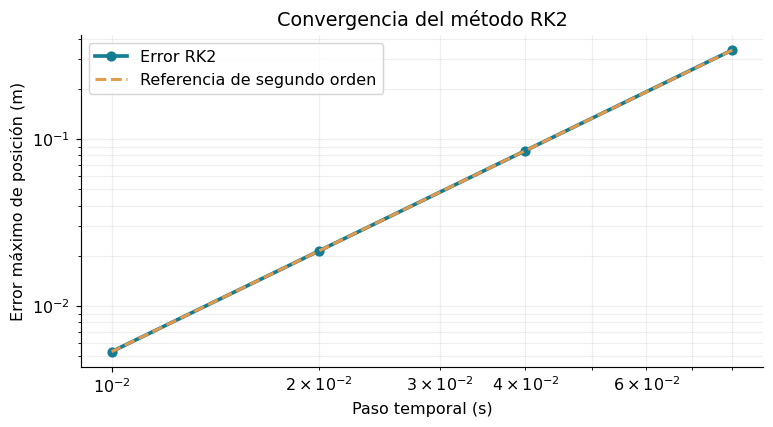

Verificación finalizada correctamente.


In [5]:

# ============================================================
# VERIFICACIÓN DE LAS IMPLEMENTACIONES
# ============================================================

set_num_threads(
    min(2, numba.config.NUMBA_NUM_THREADS)
)

resultados = []

for n in [100, 2000, 10000]:

    x0, y0 = iniciar(n)

    xs, ys = serial(
        x0, y0, DT, PASOS, R, VMAX
    )

    xp, yp = paralelo(
        x0, y0, DT, PASOS, R, VMAX
    )

    xa, ya = exacta(
        x0, y0, DT*PASOS, R, VMAX
    )

    error_paralelo = np.max(
        np.hypot(xs-xp, ys-yp)
    )

    error_analitico = np.max(
        np.hypot(xs-xa, ys-ya)
    )

    coinciden = (
        np.allclose(xs, xp, rtol=1e-10, atol=1e-10)
        and
        np.allclose(ys, yp, rtol=1e-10, atol=1e-10)
    )

    assert coinciden, "Las implementaciones no coinciden"

    resultados.append({
        "Partículas": n,
        "Error serial/paralelo (m)": error_paralelo,
        "Error respecto a solución exacta (m)": error_analitico,
        "Coinciden": coinciden
    })

tabla = pd.DataFrame(resultados)

display(tabla)

tabla.to_csv(
    "resultados/verificacion.csv",
    index=False
)

# ============================================================
# CONVERGENCIA DEL MÉTODO RK2
# ============================================================

rng = np.random.default_rng(123)

n = 250
angulos = rng.uniform(0, 2*np.pi, n)

# Radios alejados del límite del núcleo
radios = np.where(
    np.arange(n) % 2 == 0,
    10.0, 50.0
)

x0 = radios*np.cos(angulos)
y0 = radios*np.sin(angulos)

tiempo = 4.0

lista_dt = np.array([
    0.08, 0.04, 0.02, 0.01
])

xa, ya = exacta(x0, y0, tiempo, R, VMAX)

errores = []

for dt in lista_dt:

    pasos = int(round(tiempo/dt))

    xn, yn = serial(
        x0, y0, float(dt),
        pasos, R, VMAX
    )

    error = np.max(
        np.hypot(xn-xa, yn-ya)
    )

    errores.append(error)

convergencia = pd.DataFrame({
    "dt_s": lista_dt,
    "error_maximo_m": errores
})

display(convergencia)

convergencia.to_csv(
    "resultados/convergencia.csv",
    index=False
)

# Gráfica
fig, ax = plt.subplots(
    figsize=(7.5, 4.2)
)

ax.loglog(
    lista_dt, errores,
    "o-",
    color=AZUL,
    linewidth=2.5,
    label="Error RK2"
)

referencia = (
    errores[-1] *
    (lista_dt/lista_dt[-1])**2
)

ax.loglog(
    lista_dt, referencia,
    "--",
    color=NARANJA,
    linewidth=2,
    label="Referencia de segundo orden"
)

ax.set_title("Convergencia del método RK2")
ax.set_xlabel("Paso temporal (s)")
ax.set_ylabel("Error máximo de posición (m)")
ax.grid(alpha=0.2, which="both")
ax.legend()

fig.tight_layout()

fig.savefig(
    "figuras/convergencia.png",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Verificación finalizada correctamente.")


In [6]:

%%writefile medir.py

import os
import json
import platform

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numba
import psutil

from numba import set_num_threads
from modelo_vortice_uis import iniciar, serial, paralelo


BASE = Path(__file__).resolve().parent


def medir(
    tamanos=(4000, 16000, 60000),
    pasos=300,
    repeticiones=5,
    R=20.0,
    V=40.0,
    dt=0.01
):

    (BASE / "resultados").mkdir(exist_ok=True)
    (BASE / "figuras").mkdir(exist_ok=True)

    # ========================================================
    # 1. HARDWARE Y NÚMERO DE HILOS
    # ========================================================

    fisicos = psutil.cpu_count(logical=False) or 1
    logicos = os.cpu_count() or 1

    permitidos = (
        len(os.sched_getaffinity(0))
        if hasattr(os, "sched_getaffinity")
        else logicos
    )

    max_hilos = max(
        1,
        min(
            logicos,
            permitidos,
            int(numba.config.NUMBA_NUM_THREADS)
        )
    )

    candidatos = [
        1, 2, 4, 6, 8, 12, 16, 24, 32
    ]

    hilos = sorted(set(
        [p for p in candidatos if p <= max_hilos]
        + [max_hilos]
    ))

    print("Núcleos físicos reportados:", fisicos)
    print("Procesadores lógicos:", logicos)
    print("CPU permitidas:", permitidos)
    print("Hilos que se probarán:", hilos)

    # ========================================================
    # 2. CALENTAMIENTO DE NUMBA
    # ========================================================

    xt, yt = iniciar(20)

    serial(
        xt, yt, dt, 10, R, V
    )

    for p in hilos:

        set_num_threads(p)

        paralelo(
            xt, yt, dt, 10, R, V
        )

    # ========================================================
    # 3. MEDICIONES
    # ========================================================

    registros = []
    rng = np.random.default_rng(2026)

    for n in tamanos:

        x0, y0 = iniciar(n)

        configuraciones = [("Serial", 1)] + [
            ("Paralelo", p) for p in hilos
        ]

        for repeticion in range(1, repeticiones+1):

            orden = rng.permutation(
                len(configuraciones)
            )

            for j in orden:

                modo, p = configuraciones[j]

                if modo == "Paralelo":
                    set_num_threads(p)

                inicio = perf_counter()

                if modo == "Serial":

                    serial(
                        x0, y0,
                        dt, pasos, R, V
                    )

                else:

                    paralelo(
                        x0, y0,
                        dt, pasos, R, V
                    )

                tiempo = perf_counter()-inicio

                registros.append({
                    "N": n,
                    "modo": modo,
                    "hilos": p,
                    "repeticion": repeticion,
                    "segundos": tiempo
                })

        print(
            f"{n:,} partículas: completado"
        )

    # ========================================================
    # 4. ESTADÍSTICA
    # ========================================================

    mediciones = pd.DataFrame(registros)

    resumen = mediciones.groupby(
        ["N", "modo", "hilos"],
        as_index=False
    ).agg(
        mediana_s=("segundos", "median"),
        desviacion_s=("segundos", "std")
    )

    # ========================================================
    # 5. SPEEDUP Y EFICIENCIA
    # ========================================================

    resultados = []

    for n in tamanos:

        t_serial = resumen.loc[
            (resumen.N == n) &
            (resumen.modo == "Serial"),
            "mediana_s"
        ].iloc[0]

        for p in hilos:

            t_paralelo = resumen.loc[
                (resumen.N == n) &
                (resumen.modo == "Paralelo") &
                (resumen.hilos == p),
                "mediana_s"
            ].iloc[0]

            speedup = t_serial/t_paralelo

            resultados.append({
                "N": n,
                "hilos": p,
                "speedup": speedup,
                "eficiencia": speedup/p
            })

    metricas = pd.DataFrame(resultados)

    # ========================================================
    # 6. INFORMACIÓN DEL ENTORNO
    # ========================================================

    hardware = {
        "Python": platform.python_version(),
        "Sistema": platform.platform(),
        "Nucleos_fisicos_reportados": fisicos,
        "Procesadores_logicos_reportados": logicos,
        "CPU_permitidas": permitidos,
        "Hilos_maximos_Numba":
            int(numba.config.NUMBA_NUM_THREADS),
        "Hilos_probados": hilos,
        "Repeticiones": repeticiones,
        "Pasos": pasos,
        "dt": dt,
        "Radio": R,
        "Velocidad_maxima": V
    }

    # ========================================================
    # 7. EXPORTAR RESULTADOS
    # ========================================================

    mediciones.to_csv(
        BASE / "resultados/mediciones.csv",
        index=False
    )

    resumen.to_csv(
        BASE / "resultados/resumen.csv",
        index=False
    )

    metricas.to_csv(
        BASE / "resultados/metricas.csv",
        index=False
    )

    (BASE / "resultados/hardware.json").write_text(
        json.dumps(hardware, indent=2),
        encoding="utf-8"
    )

    # ========================================================
    # 8. GRÁFICA: TIEMPOS DE EJECUCIÓN
    # ========================================================

    azul = "#147D92"
    naranja = "#E59848"
    verde = "#2C917D"
    gris = "#94A3B8"

    colores = [
        naranja, verde, "#8067AC",
        "#C15F70", "#6792C8"
    ]

    fig, ax = plt.subplots(
        figsize=(8.5, 4.5)
    )

    indice_color = 0

    for (modo, p), grupo in resumen.groupby(
        ["modo", "hilos"]
    ):

        grupo = grupo.sort_values("N")

        if modo == "Serial":
            color = azul
            nombre = "Serial"
        else:
            color = colores[
                indice_color % len(colores)
            ]
            nombre = f"Paralelo ({p} hilos)"
            indice_color += 1

        ax.errorbar(
            grupo.N,
            grupo.mediana_s,
            yerr=grupo.desviacion_s,
            marker="o",
            linewidth=2,
            capsize=3,
            color=color,
            label=nombre
        )

    ax.set_title("Tiempo de ejecución")
    ax.set_xlabel("Número de partículas")
    ax.set_ylabel("Tiempo mediano (s)")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

    fig.tight_layout()

    fig.savefig(
        BASE / "figuras/tiempos.png",
        dpi=180
    )

    plt.close(fig)

    # ========================================================
    # 9. GRÁFICAS: SPEEDUP Y EFICIENCIA
    # ========================================================

    if len(hilos) >= 2:

        fig, ax = plt.subplots(
            1, 2,
            figsize=(10.5, 4.3),
            layout="constrained"
        )

        tamanos_medidos = sorted(
            metricas.N.unique()
        )

        for i, n in enumerate(tamanos_medidos):

            datos = metricas[
                metricas.N == n
            ].sort_values("hilos")

            color = [
                azul, naranja, verde
            ][i % 3]

            ax[0].plot(
                datos.hilos,
                datos.speedup,
                "o-",
                linewidth=2,
                color=color,
                label=f"{n:,} partículas"
            )

            ax[1].plot(
                datos.hilos,
                datos.eficiencia*100,
                "o-",
                linewidth=2,
                color=color,
                label=f"{n:,} partículas"
            )

        ax[0].plot(
            hilos, hilos,
            "--",
            color=gris,
            label="Ideal"
        )

        ax[1].axhline(
            100,
            linestyle="--",
            color=gris,
            label="Ideal"
        )

        ax[0].set_title("Aceleración (speedup)")
        ax[0].set_xlabel("Número de hilos")
        ax[0].set_ylabel("Speedup")

        ax[1].set_title("Eficiencia paralela")
        ax[1].set_xlabel("Número de hilos")
        ax[1].set_ylabel("Eficiencia (%)")

        for eje in ax:
            eje.set_xticks(hilos)
            eje.set_ylim(bottom=0)
            eje.grid(alpha=0.2)
            eje.legend(fontsize=8)

    else:

        fig, ax = plt.subplots(
            figsize=(8, 4.3)
        )

        ax.plot(
            metricas.N,
            metricas.speedup,
            "o-",
            linewidth=2,
            color=azul,
            label="Serial / Paralelo"
        )

        ax.axhline(
            1,
            linestyle="--",
            color=gris,
            label="Mismo tiempo"
        )

        ax.set_title("Comparación con un hilo")
        ax.set_xlabel("Número de partículas")
        ax.set_ylabel("Relación de tiempos")
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.2)
        ax.legend()

    fig.savefig(
        BASE / "figuras/desempeno.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.close(fig)

    return resumen, metricas, hardware


if __name__ == "__main__":
    medir()


Writing medir.py


## Resultados reales del computador (VS Code)

Las mediciones siguientes corresponden al Ryzen 5 3600X: 6 núcleos físicos y 12 procesadores lógicos. Los valores proceden de los archivos `resumen.csv` y `metricas.csv` generados en VS Code, **no** de Google Colab.


MEDICIONES REALES DEL PC (no Colab)


,N,modo,hilos,mediana_s,desviacion_s
0,4000,Paralelo,1,0.01677,0.00149
1,4000,Paralelo,2,0.00981,0.00066
2,4000,Paralelo,4,0.00544,0.00037
3,4000,Paralelo,6,0.00399,0.00057
4,4000,Paralelo,8,0.00299,0.00014
5,4000,Paralelo,12,0.00337,0.00057
6,4000,Serial,1,0.01672,0.00178
7,16000,Paralelo,1,0.06797,0.00317
8,16000,Paralelo,2,0.03855,0.00285
9,16000,Paralelo,4,0.01971,0.00149


SPEEDUP Y EFICIENCIA


,N,hilos,speedup,eficiencia
0,4000,1,0.9972,0.9972
1,4000,2,1.7037,0.8519
2,4000,4,3.0750,0.7687
3,4000,6,4.1855,0.6976
4,4000,8,5.6003,0.7000
5,4000,12,4.9596,0.4133
6,16000,1,0.9974,0.9974
7,16000,2,1.7584,0.8792
8,16000,4,3.4403,0.8601
9,16000,6,4.7986,0.7998


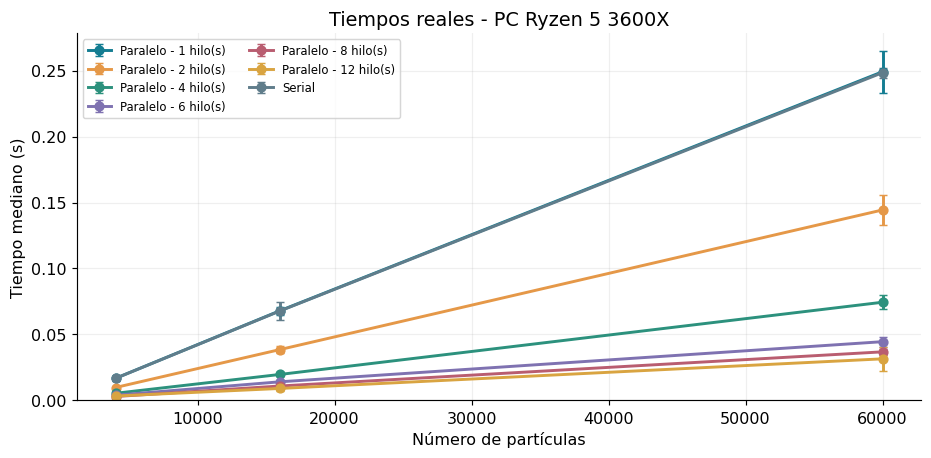

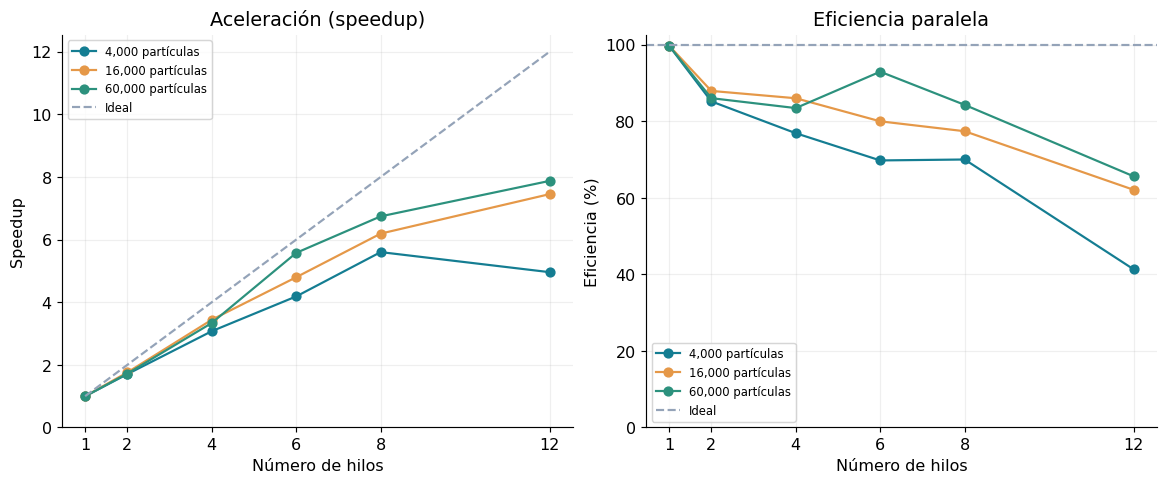

Mejor speedup: 7.87x, con 12 hilos y 60,000 partículas
Eficiencia asociada: 65.6 %


In [7]:
# ============================================================
# RESULTADOS REALES DE VS CODE - CPU LOCAL
# No se vuelve a ejecutar el benchmark de Colab.
# ============================================================

from io import StringIO
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

Path("resultados").mkdir(exist_ok=True)
Path("figuras").mkdir(exist_ok=True)

# CSV obtenidos de las mediciones reales en el PC
resumen = pd.read_csv(StringIO('N,modo,hilos,mediana_s,desviacion_s\n4000,Paralelo,1,0.016767700000855257,0.0014931541638436513\n4000,Paralelo,2,0.009814200000619167,0.0006627409235532801\n4000,Paralelo,4,0.0054376999996748054,0.0003668899537363859\n4000,Paralelo,6,0.0039949000001797685,0.0005668971276394242\n4000,Paralelo,8,0.0029856999990443,0.0001389047623322077\n4000,Paralelo,12,0.0033714000001054956,0.0005706422328432153\n4000,Serial,1,0.01672079999843845,0.0017837021568754136\n16000,Paralelo,1,0.06796869999925548,0.0031695239381737115\n16000,Paralelo,2,0.038553099999262486,0.002845070297255202\n16000,Paralelo,4,0.019705099999555387,0.0014875779993989164\n16000,Paralelo,6,0.01412720000007539,0.0011597391617267873\n16000,Paralelo,8,0.010949499999696855,0.0008508882154540267\n16000,Paralelo,12,0.00909749999846099,0.0017329975762879729\n16000,Serial,1,0.06779079999978421,0.007052835427055355\n60000,Paralelo,1,0.24909149999984947,0.015937164778159214\n60000,Paralelo,2,0.14435619999858318,0.011316617737992328\n60000,Paralelo,4,0.07442170000103943,0.005260545170432749\n60000,Paralelo,6,0.04453950000061013,0.003693067293391381\n60000,Paralelo,8,0.036837899999227375,0.0021707627724535726\n60000,Paralelo,12,0.031541100001049927,0.009131442298926753\n60000,Serial,1,0.24837470000056783,0.0037355268004793584'))
metricas = pd.read_csv(StringIO('N,hilos,speedup,eficiencia\n4000,1,0.9972029555386599,0.9972029555386599\n4000,2,1.7037354035360555,0.8518677017680277\n4000,4,3.0749765524832955,0.7687441381208239\n4000,6,4.185536558533636,0.6975894264222727\n4000,8,5.600294739521939,0.7000368424402423\n4000,12,4.959601351935468,0.41330011266128897\n16000,1,0.9973826187719758,0.9973826187719758\n16000,2,1.758374812948402,0.879187406474201\n16000,4,3.4402667330444303,0.8600666832611076\n16000,6,4.798601279759786,0.7997668799599643\n16000,8,6.19122334368337,0.7739029179604212\n16000,12,7.451585601676536,0.620965466806378\n60000,1,0.9971223425958651,0.9971223425958651\n60000,2,1.720568288739975,0.8602841443699875\n60000,4,3.3373962163871407,0.8343490540967852\n60000,6,5.576504002001941,0.9294173336669901\n60000,8,6.742368593371966,0.8427960741714957\n60000,12,7.874636585036668,0.6562197154197223'))

resumen.to_csv("resultados/resumen_PC.csv", index=False)
metricas.to_csv("resultados/metricas_PC.csv", index=False)

hardware = {
    "Entorno": "VS Code en Windows (mediciones locales)",
    "CPU": "AMD Ryzen 5 3600X",
    "Nucleos_fisicos_reportados": 6,
    "Procesadores_logicos_reportados": 12,
    "Hilos_probados": [1, 2, 4, 6, 8, 12],
    "Repeticiones": 5,
    "Pasos": 300,
    "Origen_de_los_datos": "resumen.csv y metricas.csv exportados desde medir.py en VS Code"
}

print("MEDICIONES REALES DEL PC (no Colab)")
display(resumen.round(5))
print("SPEEDUP Y EFICIENCIA")
display(metricas.round(4))

AZUL_PC, NARANJA_PC, VERDE_PC = "#147D92", "#E59848", "#2C917D"

# Figura 1: tiempo serial frente a las configuraciones paralelas
fig, ax = plt.subplots(figsize=(9, 4.5))
colores = [AZUL_PC, NARANJA_PC, VERDE_PC, "#7F72B1", "#B95D70", "#D9A441", "#607D8B"]
for idx, ((modo, hilos), grupo) in enumerate(resumen.groupby(["modo", "hilos"])):
    grupo = grupo.sort_values("N")
    etiqueta = "Serial" if modo == "Serial" else f"Paralelo - {hilos} hilo(s)"
    ax.errorbar(grupo["N"], grupo["mediana_s"], yerr=grupo["desviacion_s"],
                marker="o", linewidth=2, capsize=3, color=colores[idx % len(colores)], label=etiqueta)
ax.set(title="Tiempos reales - PC Ryzen 5 3600X", xlabel="Número de partículas", ylabel="Tiempo mediano (s)")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig("figuras/tiempos_PC.png", dpi=180, bbox_inches="tight")
plt.show()

# Figura 2: speedup y eficiencia para tres tamaños
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
tamanos = sorted(metricas["N"].unique())
colores_n = [AZUL_PC, NARANJA_PC, VERDE_PC]
for i, n in enumerate(tamanos):
    grupo = metricas[metricas["N"] == n].sort_values("hilos")
    axes[0].plot(grupo["hilos"], grupo["speedup"], "o-", color=colores_n[i], label=f"{n:,} partículas")
    axes[1].plot(grupo["hilos"], grupo["eficiencia"] * 100, "o-", color=colores_n[i], label=f"{n:,} partículas")
hilos = sorted(metricas["hilos"].unique())
axes[0].plot(hilos, hilos, "--", color="#94A3B8", label="Ideal")
axes[1].axhline(100, linestyle="--", color="#94A3B8", label="Ideal")
axes[0].set(title="Aceleración (speedup)", xlabel="Número de hilos", ylabel="Speedup")
axes[1].set(title="Eficiencia paralela", xlabel="Número de hilos", ylabel="Eficiencia (%)")
for ax in axes:
    ax.set_xticks(hilos)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.savefig("figuras/desempeno_PC.png", dpi=180, bbox_inches="tight")
plt.show()

# Mejor aceleración multihilo del experimento
candidatos = metricas[metricas["hilos"] > 1]
mejor = candidatos.loc[candidatos["speedup"].idxmax()]
print(f"Mejor speedup: {mejor['speedup']:.2f}x, con {int(mejor['hilos'])} hilos y {int(mejor['N']):,} partículas")
print(f"Eficiencia asociada: {100*mejor['eficiencia']:.1f} %")


In [8]:

# ============================================================
# CONCLUSIONES AUTOMÁTICAS
# ============================================================

if metricas["hilos"].max() > 1:

    if mejor["speedup"] > 1:

        resultado = (
            f"La implementación paralela obtuvo una "
            f"aceleración máxima de "
            f"**{mejor['speedup']:.2f} veces**, "
            f"utilizando **{int(mejor['hilos'])} hilos**."
        )

    else:

        resultado = (
            "La implementación paralela no logró "
            "superar el rendimiento serial en las "
            "configuraciones multihilo evaluadas."
        )

else:

    resultado = (
        "El entorno únicamente permitió evaluar un "
        "hilo, por lo que no fue posible medir una "
        "aceleración multihilo."
    )

display(Markdown(f"""
## Resultados y discusión

### 1. Comportamiento físico

El modelo de Rankine permitió representar un flujo
giratorio cuyo perfil de velocidad aumenta dentro
del núcleo y disminuye fuera de este.

Las partículas trazadoras siguieron trayectorias
aproximadamente circulares, de acuerdo con las
características del campo de velocidades.

### 2. Método numérico

Se utilizó RK2 para actualizar las posiciones.

La comparación con la solución analítica permitió
evaluar el error y estudiar su disminución al
reducir el paso temporal.

### 3. Implementaciones

Se desarrollaron dos versiones del mismo algoritmo:

- Serial: procesamiento secuencial mediante `range`.
- Paralela: distribución de partículas mediante `prange`.

Las dos implementaciones produjeron resultados
numéricamente equivalentes.

### 4. Rendimiento computacional

{resultado}

Se realizaron cinco mediciones por configuración.
Se utilizaron la mediana y la desviación estándar
para analizar los tiempos de ejecución.

El rendimiento depende del número de partículas,
los hilos disponibles y los costos de paralelización.

### 5. Limitaciones

El modelo es bidimensional, estacionario e idealizado.

No reproduce la formación de tornados reales,
la turbulencia atmosférica ni los movimientos
verticales del aire.

### Conclusión general

El proyecto permitió integrar modelamiento físico,
algoritmos numéricos, programación serial y paralela,
verificación y análisis del rendimiento computacional.
"""))



## Resultados y discusión

### 1. Comportamiento físico

El modelo de Rankine permitió representar un flujo
giratorio cuyo perfil de velocidad aumenta dentro
del núcleo y disminuye fuera de este.

Las partículas trazadoras siguieron trayectorias
aproximadamente circulares, de acuerdo con las
características del campo de velocidades.

### 2. Método numérico

Se utilizó RK2 para actualizar las posiciones.

La comparación con la solución analítica permitió
evaluar el error y estudiar su disminución al
reducir el paso temporal.

### 3. Implementaciones

Se desarrollaron dos versiones del mismo algoritmo:

- Serial: procesamiento secuencial mediante `range`.
- Paralela: distribución de partículas mediante `prange`.

Las dos implementaciones produjeron resultados
numéricamente equivalentes.

### 4. Rendimiento computacional

La implementación paralela obtuvo una aceleración máxima de **7.87 veces**, utilizando **12 hilos**.

Se realizaron cinco mediciones por configuración.
Se utilizaron la mediana y la desviación estándar
para analizar los tiempos de ejecución.

El rendimiento depende del número de partículas,
los hilos disponibles y los costos de paralelización.

### 5. Limitaciones

El modelo es bidimensional, estacionario e idealizado.

No reproduce la formación de tornados reales,
la turbulencia atmosférica ni los movimientos
verticales del aire.

### Conclusión general

El proyecto permitió integrar modelamiento físico,
algoritmos numéricos, programación serial y paralela,
verificación y análisis del rendimiento computacional.


In [9]:

from importlib.metadata import version

# ============================================================
# 1. DEPENDENCIAS
# ============================================================

librerias = [
    "numpy",
    "numba",
    "matplotlib",
    "pandas",
    "ipywidgets",
    "psutil"
]

requirements = "\n".join(
    f"{lib}=={version(lib)}"
    for lib in librerias
)

Path("requirements.txt").write_text(
    requirements + "\n",
    encoding="utf-8"
)

# ============================================================
# 2. DOCUMENTACIÓN
# ============================================================

readme = f"""
# Simulación computacional del movimiento del aire

Universidad Industrial de Santander
Algoritmos Computacionales
Proyecto final — 2026

## Objetivo

Modelar el movimiento giratorio del aire mediante
el vórtice de Rankine y comparar implementaciones
seriales y paralelas.

## Modelo físico

Vórtice de Rankine:

Interior: v = Vmax*r/R
Exterior: v = Vmax*R/r

Modelo horizontal bidimensional y estacionario.

Parámetros iniciales:
R = 20 m
Vmax = 40 m/s

Son valores ilustrativos, no datos de un tornado
real específico.

## Método numérico

Runge-Kutta de segundo orden (RK2).

## Implementación

modelo_vortice_uis.py:
- Generación de partículas
- Campo de velocidades
- Método RK2
- Algoritmo serial
- Algoritmo paralelo
- Trayectorias
- Solución analítica

medir.py:
- Mediciones de tiempos
- Configuraciones de hilos
- Speedup y eficiencia
- Generación de gráficas
- Registro del hardware

## Reproducibilidad

1. Instalar las dependencias:

pip install -r requirements.txt

2. Abrir el notebook en Google Colab
   y ejecutar las celdas en orden.

3. Para repetir las mediciones:

python medir.py

4. Consultar las figuras y archivos CSV.

Las mediciones excluyen el calentamiento JIT.

Se utilizan cinco repeticiones por configuración,
con mediana y desviación estándar.

## Hardware utilizado

{json.dumps(hardware, indent=2, ensure_ascii=False)}

## Resultados

{resultado}

## Limitaciones

La simulación representa un vórtice idealizado
en dos dimensiones.

No se incluyen turbulencia, formación real
del tornado ni corrientes verticales.

## Bibliografía

NOAA - Tornado Basics
https://www.nssl.noaa.gov/education/svrwx101/tornadoes/

Wood y White (2011)
A New Parametric Model of Vortex Tangential-Wind
Profiles: Development, Testing, and Verification
https://doi.org/10.1175/2011JAS3588.1

Numba - Parallelization
https://numba.readthedocs.io/en/stable/user/parallel.html

NumPy - allclose
https://numpy.org/doc/stable/reference/generated/numpy.allclose.html

Python - perf_counter
https://docs.python.org/3/library/time.html#time.perf_counter

Matplotlib - Animations
https://matplotlib.org/stable/users/explain/animations/animations.html
"""

Path("README.md").write_text(
    readme.strip() + "\n",
    encoding="utf-8"
)

# ============================================================
# 3. COMPROBAR ARCHIVOS
# ============================================================

archivos = [
    Path("modelo_vortice_uis.py"),
    Path("medir.py"),
    Path("README.md"),
    Path("requirements.txt")
]

for carpeta in ["figuras", "resultados"]:

    archivos.extend(
        archivo
        for archivo in Path(carpeta).rglob("*")
        if archivo.is_file()
    )

# ============================================================
# 4. CREAR ZIP
# ============================================================

nombre_zip = "Proyecto_Tornado_UIS.zip"

with zipfile.ZipFile(
    nombre_zip,
    "w",
    zipfile.ZIP_DEFLATED
) as paquete:

    for archivo in archivos:

        if archivo.is_file():

            paquete.write(
                archivo,
                arcname=str(archivo)
            )

print("PROYECTO FINAL PREPARADO")
print("=" * 45)

for archivo in archivos:

    if archivo.is_file():
        print("✓", archivo)

print("\nArchivo:", nombre_zip)

# ============================================================
# 5. DESCARGAR
# ============================================================

try:
    from google.colab import files
    files.download(nombre_zip)

except ImportError:
    print("ZIP guardado:", nombre_zip)


PROYECTO FINAL PREPARADO
✓ modelo_vortice_uis.py
✓ medir.py
✓ README.md
✓ requirements.txt
✓ figuras/perfil_velocidad.png
✓ figuras/campo_velocidades.png
✓ figuras/tiempos_PC.png
✓ figuras/animacion.html
✓ figuras/convergencia.png
✓ figuras/desempeno_PC.png
✓ resultados/convergencia.csv
✓ resultados/verificacion.csv
✓ resultados/resumen_PC.csv
✓ resultados/metricas_PC.csv

Archivo: Proyecto_Tornado_UIS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>